In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data=pd.read_csv(r"/content/churn.csv")

In [3]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
## NUll check
round(data.isnull().mean()*100,2)

,0
customerID,0.0
gender,0.0
SeniorCitizen,0.0
Partner,0.0
Dependents,0.0
tenure,0.0
PhoneService,0.0
MultipleLines,0.0
InternetService,0.0
OnlineSecurity,0.0


In [5]:
### Duplicate check
data.duplicated().sum()

np.int64(0)

In [6]:
#### Data Type Check
data.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Since TotalCharges has Wrong Datatypes we have to change them to correct Datatype and if you see the values for Senior Citizen are numerical values  0s and 1s,we have to convert them to categorical data(No,Yes)

In [7]:

### convert senior citizen col from int to object(values from 0 or  1 to no or yes)
data["SeniorCitizen"]=data["SeniorCitizen"].replace({0:"No",1:"Yes"})


In [8]:
data["SeniorCitizen"]

,SeniorCitizen
0,No
1,No
2,No
3,No
4,No
...,...
7038,No
7039,No
7040,No
7041,Yes


SeniorCitizen col has been converted into categorical data.

In [9]:
### Check whether Total CHarges has empty values
empty_spaces=0
for  i in data["TotalCharges"]:
  if i ==" ":
    empty_spaces+=1
print(empty_spaces)

11


In [10]:
### convert Total Charges from object dtype into float and make empty spaces as nan
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

Now ,TotalCharges field converted into float and also we modified the empty spaces as nan.


In [11]:
### count of categorical and numerical data
categorical_cols=0
numerical_cols=0

for i in data.dtypes:
  if i =="object":
    categorical_cols+=1
  else:
    numerical_cols+=1

print("Categorical cols:", categorical_cols)
print("Numerical cols:", numerical_cols)



Categorical cols: 18
Numerical cols: 3


In [12]:
## Empty Spaces check for all columns
empty_space_cols=0
for col in data.columns:
    # Count values that are empty strings or only whitespace
    empty_spaces = (data[col].astype(str).str.strip() == '').sum()
    if empty_spaces > 0:
        print(f"Column '{col}' has {empty_spaces} empty space(s)")
        empty_space_cols+=1
if empty_space_cols==0:
  print("No Empty Spaces")



No Empty Spaces


Now ,we don't have  Empty spaces for any column

In [13]:
data.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In TotalCharges field,As we changed empty spaces into nan values,we got 11  Null Values,Now we have to look at them.

In [14]:
### Inspect Null values
data[data["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [15]:
## convert NAN to 0 for TotalCharges column
data["TotalCharges"]=data["TotalCharges"].fillna(0)

In [16]:
data["TotalCharges"].isnull().sum()

np.int64(0)

## Handling Missing Values in TotalCharges

The `TotalCharges` column contained 11 missing values. After investigation, I found that all 11 corresponding customers had zero tenure. Since `MonthlyCharges` represents the monthly plan price and does not necessarily indicate an amount already billed, I replaced the missing `TotalCharges` values with zero as a practical assumption. The original `Churn` labels were preserved.

### Data Cleaning — Findings

- Converted `TotalCharges` from object to numeric format.
- Converted `SeniorCitizen` from 0/1 into No/Yes categories.
- Found 11 missing values in `TotalCharges`, all associated with customers having zero tenure.
- Replaced these missing values with zero as a practical assumption and preserved the original churn labels.
- Checked the dataset for duplicate rows and empty strings.

In [17]:
data.describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [18]:
data.dtypes

,0
customerID,object
gender,object
SeniorCitizen,object
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [19]:
## Value Counts for all categorical cols
count=0
for i in data.columns:
  if data[i].dtype=="object":
    print(data[i].value_counts())
    print()
    count+=1
print("Total Categorical Cols:",count)


customerID
3186-AJIEK    1
7590-VHVEG    1
5575-GNVDE    1
8775-CEBBJ    1
2823-LKABH    1
             ..
6713-OKOMC    1
1452-KIOVK    1
9305-CDSKC    1
9237-HQITU    1
7795-CFOCW    1
Name: count, Length: 7043, dtype: int64

gender
Male      3555
Female    3488
Name: count, dtype: int64

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64

Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dty

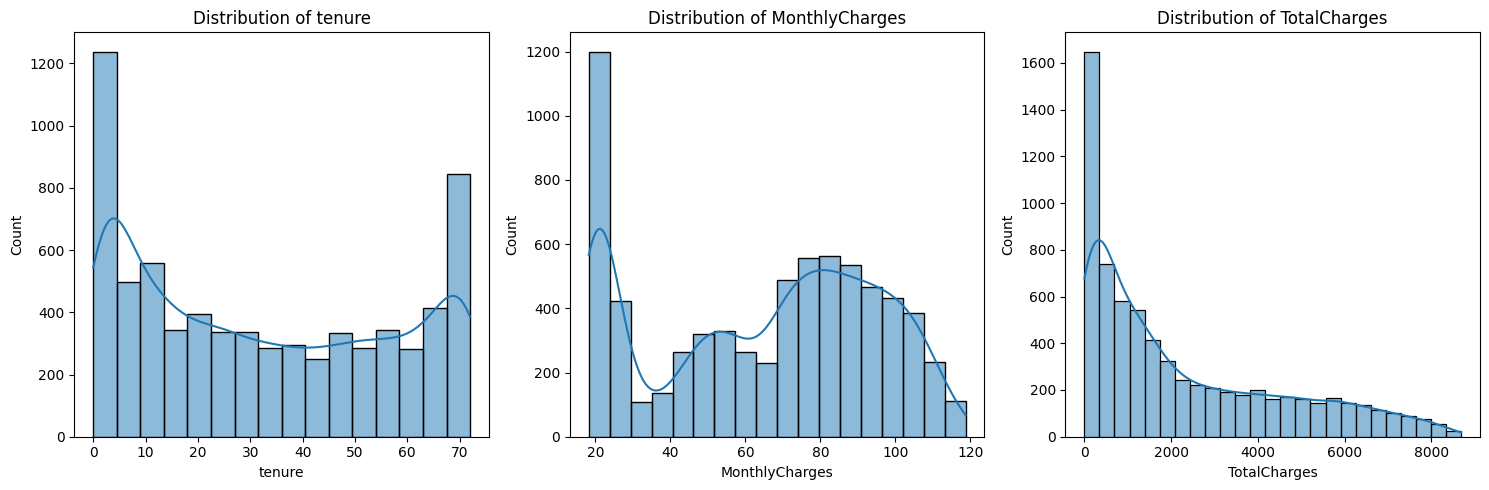

In [20]:
### Numerical columns into KDE plots
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
cols = ["tenure", "MonthlyCharges", "TotalCharges"]
for col, a in zip(cols, ax):
    sns.histplot(data=data, x=col, ax=a, kde=True)
    a.set_xlabel(col)
    a.set_ylabel("Count")
    a.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()




### Numerical Feature Distributions

- Examined the distributions of `tenure`, `MonthlyCharges`, and `TotalCharges` using histograms.
- These plots help identify skewness, concentration of values, and the spread of customer charges and tenure.


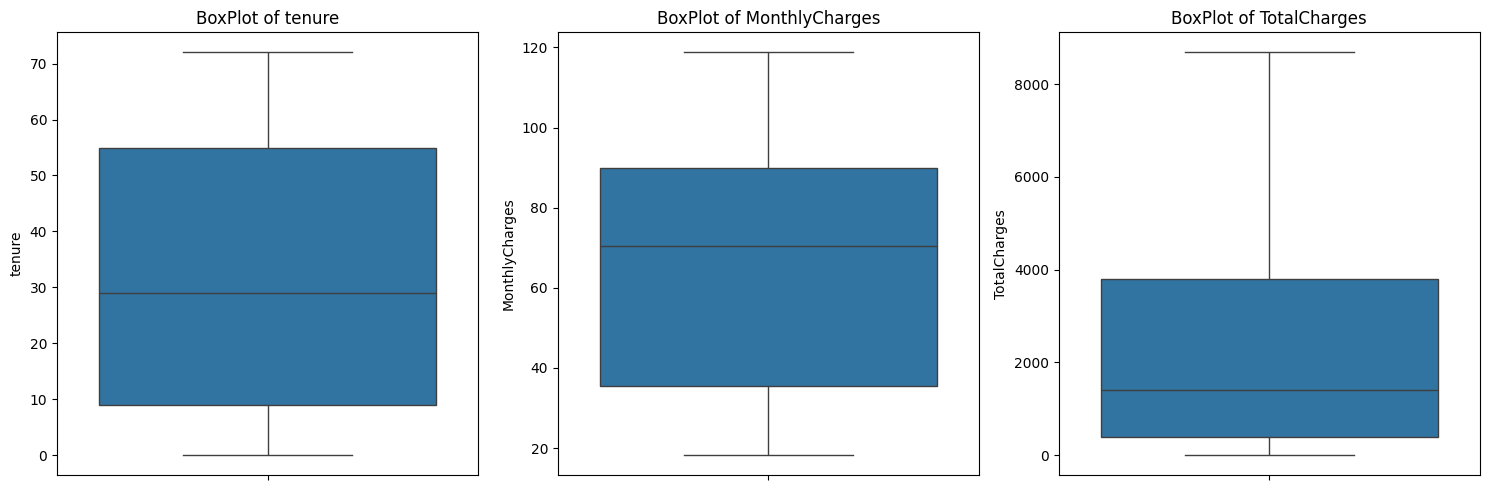

In [21]:
### OUTliers check fo rNumerical cols
fig,ax=plt.subplots(1,3,figsize=(15,5))
cols=["tenure","MonthlyCharges","TotalCharges"]
for col,a in zip(cols,ax):
  sns.boxplot(data=data,y=col,ax=a)
  a.set_title(f"BoxPlot of {col}")
plt.tight_layout()
plt.show()

### Outlier Analysis

- Used boxplots to inspect potential outliers in the numerical features.
- As we see,we don't have outliers in any numerical columns.

churn-value counts Churn
No     5174
Yes    1869
Name: count, dtype: int64
percentage for churned and not churn Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


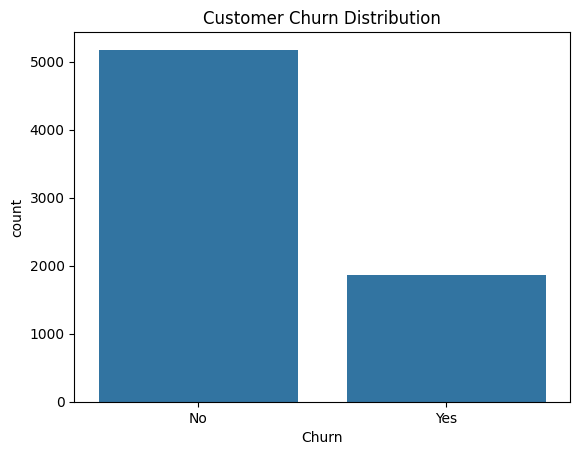

In [22]:
### TARGET COLUMN
print("churn-value counts",data["Churn"].value_counts())
print("percentage for churned and not churn",round(data["Churn"].value_counts(normalize=True)*100,2))

sns.countplot(data=data,x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

### Churn Distribution

- Examined the number and percentage of customers who churned and those who stayed.
- Compared the distribution of the two target classes to determine whether the dataset is imbalanced.
- This will inform model evaluation, particularly the use of precision, recall, F1-score, and ROC-AUC.

In [23]:
### Categorical data vs churn
cat_cols = data.select_dtypes(include="object").columns

for col in cat_cols:
  if col in ["customerID", "Churn"]:
    continue
  rates = round(pd.crosstab(data[col], data["Churn"],normalize="index")*100,2)
  print(rates)
  print()





Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16

Churn             No    Yes
SeniorCitizen              
No             76.39  23.61
Yes            58.32  41.68

Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66

Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45

Churn            No    Yes
PhoneService              
No            75.07  24.93
Yes           73.29  26.71

Churn                No    Yes
MultipleLines                 
No                74.96  25.04
No phone service  75.07  24.93
Yes               71.39  28.61

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61

Churn                   N

### Categorical Features and Churn

- Compared churn percentages across categories of each categorical feature.
- Identified groups with relatively high and low churn rates.
- These relationships may help identify useful predictors of customer churn, but they do not establish causation.

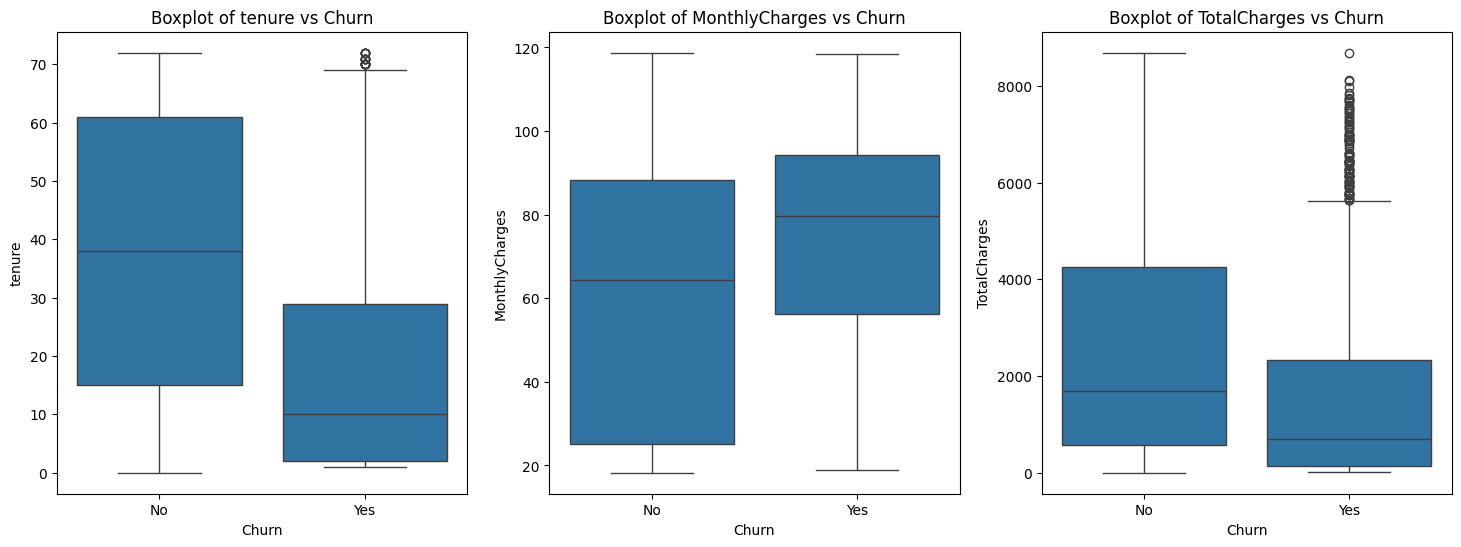

In [24]:
#### Numerical Features vs Target variable
num_cols=data.select_dtypes(exclude="object")
fig,ax=plt.subplots(1,3,figsize=(18,6))

for col,ax in zip(num_cols.columns,ax):
  sns.boxplot(data=data,x="Churn",y=col,ax=ax)
  ax.set_title(f"Boxplot of {col} vs Churn")



### Numerical Features and Churn

- Compared tenure, monthly charges, and total charges between customers who churned and those who stayed.
- Used boxplots and mean/median statistics to examine differences between the groups.
- The observed differences will help guide feature selection and interpretation during modeling.

In [25]:
## Mean ,Medianvalues for Numerical cols
for i in num_cols:
   print(i)
   print(data.groupby("Churn")[i].agg(["mean","median"]).round(2))
   print()

tenure
        mean  median
Churn               
No     37.57    38.0
Yes    17.98    10.0

MonthlyCharges
        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65

TotalCharges
          mean   median
Churn                  
No     2549.91  1679.52
Yes    1531.80   703.55



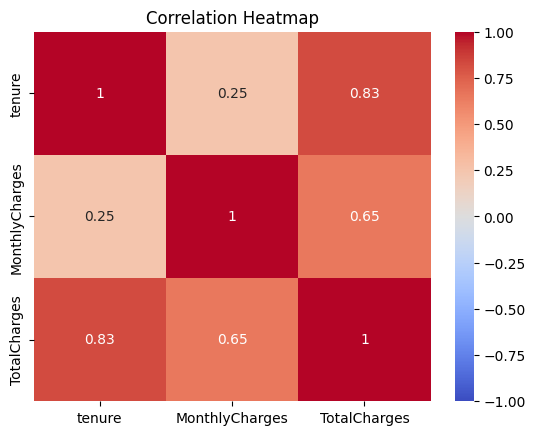

In [26]:
### Correlation HeatMap for numerical cols
corr=data.corr(numeric_only=True)

sns.heatmap(corr,annot=True,cmap="coolwarm",vmin=-1,vmax=1)
plt.title("Correlation Heatmap")
plt.show()

### Correlation Analysis

- Examined correlations between numerical features using a heatmap.
- Correlation indicates the strength and direction of a linear relationship.
- Correlation does not establish causation, and this heatmap does not include the categorical features.

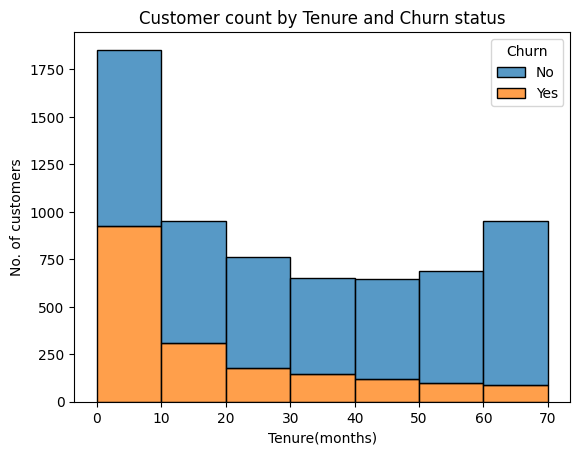

In [27]:
### Churn rate by Tenure
bin=[0,10,20,30,40,50,60,70]
sns.histplot(data=data, x="tenure", hue="Churn",bins=bin, multiple="stack")
plt.title("Customer count by Tenure and Churn status")
plt.xlabel("Tenure(months)")
plt.ylabel("No. of customers")
plt.show()

In [28]:
print("Dataset shape:", data.shape)
print("Duplicate rows:", data.duplicated().sum())
print("Missing values:")
print(data.isnull().sum()[data.isnull().sum() > 0])
print("Data types:")
print(data.dtypes)

Dataset shape: (7043, 21)
Duplicate rows: 0
Missing values:
Series([], dtype: int64)
Data types:
customerID           object
gender               object
SeniorCitizen        object
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


## Key Findings from Exploratory Data Analysis

1. **Data quality:** Summarize the missing values, duplicate check, and data-type corrections.
2. **Churn distribution:** State the percentage of customers who churned and those who stayed.
3. **Contract and services:** Identify the categorical groups with the highest churn rates based on your results.
4. **Tenure:** Describe how tenure differs between churned and retained customers.
5. **Charges:** Explain any observed differences in monthly and total charges.
6. **Modeling implications:** Identify features that may be useful for predicting churn and note any class imbalance that should be considered during evaluation.

In [29]:
## ML steps:
data_ml=data.copy()

data_ml.drop(columns=["customerID"],inplace=True)

In [30]:
data_ml.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [31]:
### Input and Output variables splitting
output_var=data_ml["Churn"]
input_var=data_ml.drop(columns=["Churn"])

In [32]:
## Encode cat variables into numerical
input_var.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='object')

In [33]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder

In [34]:
### Encoding output ariable
output_var=output_var.map({"No":0,"Yes":1})

In [35]:
output_var


,Churn
0,0
1,0
2,1
3,0
4,1
...,...
7038,0
7039,0
7040,0
7041,1


In [36]:
input_var.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='object')

In [37]:
### Encoding categorical input variables

## 1)gender-male,female------------->male-1,female-0
ohe = OneHotEncoder(sparse_output=False, drop="first",dtype="int")
gender_encoded = ohe.fit_transform(input_var[["gender"]])

### Drop the gender col
input_var.drop(columns=["gender"], inplace=True)

## Adding the encoded column
input_var["gender"] = gender_encoded

input_var.head()

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender
0,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,1
2,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,1
4,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0


In [38]:
### 2)encoding Senior citizen col
### seniorcitizen no ,yes -------------->0,1

citizen_encoded = ohe.fit_transform(input_var[["SeniorCitizen"]])

### Drop the SeniorCitizen  col
input_var.drop(columns=["SeniorCitizen"], inplace=True)

## Adding the encoded column
input_var["SeniorCitizen"] = citizen_encoded

input_var.head()


,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen
0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0
1,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,1,0
2,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0
3,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,1,0
4,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,0


In [39]:
### 3)encoding Partner col
###  from no ,yes -------------->0,1

partner_encoded = ohe.fit_transform(input_var[["Partner"]])

### Drop the col
input_var.drop(columns=["Partner"], inplace=True)

## Adding the encoded column
input_var["Partner"] = partner_encoded

input_var.head()


,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner
0,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,1
1,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,1,0,0
2,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0,0
3,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,1,0,0
4,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,0,0


In [40]:
### 4)encoding Dpendents col
###  from no ,yes -------------->0,1

dependence_encoded = ohe.fit_transform(input_var[["Dependents"]])

### Drop the col
input_var.drop(columns=["Dependents"], inplace=True)

## Adding the encoded column
input_var["Dependents"] = dependence_encoded

input_var.head()


,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents
0,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,1,0
1,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,1,0,0,0
2,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0,0,0
3,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,1,0,0,0
4,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,0,0,0


In [41]:
### 5)encoding PhoneService col
###  from no ,yes -------------->0,1

phone_encoded = ohe.fit_transform(input_var[["PhoneService"]])

### Drop the  col
input_var.drop(columns=["PhoneService"], inplace=True)

## Adding the encoded column
input_var["PhoneService"] = phone_encoded

input_var.head()


,tenure,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService
0,1,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,1,0,0
1,34,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,1,0,0,0,1
2,2,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0,0,0,1
3,45,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,1,0,0,0,0
4,2,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,0,0,0,1


In [42]:
### 6)MultipleLines Partner col
###  from no ,yes -------------->0,1

multiline_encoded = ohe.fit_transform(input_var[["MultipleLines"]])

## get the features name
new_cols=ohe.get_feature_names_out(["MultipleLines"])

### Drop the col
input_var.drop(columns=["MultipleLines"], inplace=True)

## Adding new encoded columns
input_var[new_cols] = multiline_encoded

input_var.head()


,tenure,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines_No phone service,MultipleLines_Yes
0,1,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,1,0,0,1,0
1,34,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,1,0,0,0,1,0,0
2,2,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0,0,0,1,0,0
3,45,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,1,0,0,0,0,1,0
4,2,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,0,0,0,1,0,0


In [43]:
### 7)encoding InternetSerice col
###  from no ,yes -------------->0,1

is_encoded = ohe.fit_transform(input_var[["InternetService"]])

## get the features name
new_cols=ohe.get_feature_names_out(["InternetService"])

### Drop the col
input_var.drop(columns=["InternetService"], inplace=True)

## Adding new encoded columns
input_var[new_cols] = is_encoded

input_var.head()


,tenure,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,...,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No
0,1,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,...,29.85,0,0,1,0,0,1,0,0,0
1,34,Yes,No,Yes,No,No,No,One year,No,Mailed check,...,1889.50,1,0,0,0,1,0,0,0,0
2,2,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,...,108.15,1,0,0,0,1,0,0,0,0
3,45,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),...,1840.75,1,0,0,0,0,1,0,0,0
4,2,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,...,151.65,0,0,0,0,1,0,0,1,0


In [44]:
### 8)encoding Partner col
###  from no ,yes -------------->0,1

os_encoded = ohe.fit_transform(input_var[["OnlineSecurity"]])

## get the features name
new_cols=ohe.get_feature_names_out(["OnlineSecurity"])

### Drop the col
input_var.drop(columns=["OnlineSecurity"], inplace=True)

## Adding new encoded columns
input_var[new_cols] = os_encoded

input_var.head()


,tenure,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,...,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes
0,1,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,...,0,1,0,0,1,0,0,0,0,0
1,34,No,Yes,No,No,No,One year,No,Mailed check,56.95,...,0,0,0,1,0,0,0,0,0,1
2,2,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,...,0,0,0,1,0,0,0,0,0,1
3,45,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,...,0,0,0,0,1,0,0,0,0,1
4,2,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,...,0,0,0,1,0,0,1,0,0,0


In [45]:
### 9)encoding onlinebackup col
###  from no ,yes -------------->0,1

ob_encoded = ohe.fit_transform(input_var[["OnlineBackup"]])

## get the features name
new_cols=ohe.get_feature_names_out(["OnlineBackup"])

### Drop the col
input_var.drop(columns=["OnlineBackup"], inplace=True)

## Adding new encoded columns
input_var[new_cols] = ob_encoded

input_var.head()


,tenure,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,...,Dependents,PhoneService,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes
0,1,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,...,0,0,1,0,0,0,0,0,0,1
1,34,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,...,0,1,0,0,0,0,0,1,0,0
2,2,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,...,0,1,0,0,0,0,0,1,0,1
3,45,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,...,0,0,1,0,0,0,0,1,0,0
4,2,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,...,0,1,0,0,1,0,0,0,0,0


In [46]:
### 10)encoding deviceProtection col
###  from no ,yes -------------->0,1

dp_encoded = ohe.fit_transform(input_var[["DeviceProtection"]])

## get the features name
new_cols=ohe.get_feature_names_out(["DeviceProtection"])

### Drop the col
input_var.drop(columns=["DeviceProtection"], inplace=True)

## Adding new encoded columns
input_var[new_cols] = dp_encoded

input_var.head()


,tenure,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,...,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes
0,1,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,...,1,0,0,0,0,0,0,1,0,0
1,34,No,No,No,One year,No,Mailed check,56.95,1889.50,1,...,0,0,0,0,0,1,0,0,0,1
2,2,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,...,0,0,0,0,0,1,0,1,0,0
3,45,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,1,...,1,0,0,0,0,1,0,0,0,1
4,2,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,...,0,0,1,0,0,0,0,0,0,0


In [47]:
### 11)encoding TechSupport col
###  from no ,yes -------------->0,1

ts_encoded = ohe.fit_transform(input_var[["TechSupport"]])

## get the features name
new_cols=ohe.get_feature_names_out(["TechSupport"])

### Drop the col
input_var.drop(columns=["TechSupport"], inplace=True)

## Adding new encoded columns
input_var[new_cols] = ts_encoded

input_var.head()


,tenure,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,...,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes
0,1,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,...,0,0,0,0,0,1,0,0,0,0
1,34,No,No,One year,No,Mailed check,56.95,1889.50,1,0,...,0,0,0,1,0,0,0,1,0,0
2,2,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0,...,0,0,0,1,0,1,0,0,0,0
3,45,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,1,0,...,0,0,0,1,0,0,0,1,0,1
4,2,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,0,...,1,0,0,0,0,0,0,0,0,0


In [48]:
### 12)encoding StreamingTv col
###  from no ,yes -------------->0,1

st_encoded = ohe.fit_transform(input_var[["StreamingTV"]])

## get the features name
new_cols=ohe.get_feature_names_out(["StreamingTV"])

### Drop the col
input_var.drop(columns=["StreamingTV"], inplace=True)

## Adding new encoded columns
input_var[new_cols] = st_encoded

input_var.head()


,tenure,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,...,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes
0,1,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,1,...,0,0,0,1,0,0,0,0,0,0
1,34,No,One year,No,Mailed check,56.95,1889.50,1,0,0,...,0,1,0,0,0,1,0,0,0,0
2,2,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0,0,...,0,1,0,1,0,0,0,0,0,0
3,45,No,One year,No,Bank transfer (automatic),42.30,1840.75,1,0,0,...,0,1,0,0,0,1,0,1,0,0
4,2,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [49]:
### 13)encoding  StreamingMovies col
###  from no ,yes -------------->0,1

sm_encoded = ohe.fit_transform(input_var[["StreamingMovies"]])

## get the features name
new_cols=ohe.get_feature_names_out(["StreamingMovies"])

### Drop the  col
input_var.drop(columns=["StreamingMovies"], inplace=True)

## Adding new encoded columns
input_var[new_cols] = sm_encoded

input_var.head()


,tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,...,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes
0,1,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,1,0,...,0,1,0,0,0,0,0,0,0,0
1,34,One year,No,Mailed check,56.95,1889.50,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,2,Month-to-month,Yes,Mailed check,53.85,108.15,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0
3,45,One year,No,Bank transfer (automatic),42.30,1840.75,1,0,0,0,...,0,0,0,1,0,1,0,0,0,0
4,2,Month-to-month,Yes,Electronic check,70.70,151.65,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [50]:
### 14)encoding PaperlessBilling col
###  from no ,yes -------------->0,1

pb_encoded = ohe.fit_transform(input_var[["PaperlessBilling"]])

### Drop the PaperlessBilling col
input_var.drop(columns=["PaperlessBilling"], inplace=True)

## Adding new encoded columns
input_var["PaperlessBilling"] = pb_encoded

input_var.head()


,tenure,Contract,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,...,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling
0,1,Month-to-month,Electronic check,29.85,29.85,0,0,1,0,0,...,1,0,0,0,0,0,0,0,0,1
1,34,One year,Mailed check,56.95,1889.50,1,0,0,0,1,...,0,0,1,0,0,0,0,0,0,0
2,2,Month-to-month,Mailed check,53.85,108.15,1,0,0,0,1,...,1,0,0,0,0,0,0,0,0,1
3,45,One year,Bank transfer (automatic),42.30,1840.75,1,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
4,2,Month-to-month,Electronic check,70.70,151.65,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1


In [51]:
### 15)encoding PaymentMethod col
###  from no ,yes -------------->0,1

pm_encoded = ohe.fit_transform(input_var[["PaymentMethod"]])

## get the features name
new_cols=ohe.get_feature_names_out(["PaymentMethod"])

### Drop the  col
input_var.drop(columns=["PaymentMethod"], inplace=True)

## Adding new encoded columns
input_var[new_cols] = pm_encoded

input_var.head()


,tenure,Contract,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines_No phone service,...,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,Month-to-month,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,34,One year,56.95,1889.50,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
2,2,Month-to-month,53.85,108.15,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,45,One year,42.30,1840.75,1,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
4,2,Month-to-month,70.70,151.65,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [52]:
### 16)encoding Contract col
###  from no ,yes -------------->0,1

c_encoded = ohe.fit_transform(input_var[["Contract"]])

## get the features name
new_cols=ohe.get_feature_names_out(["Contract"])

### Drop the  col
input_var.drop(columns=["Contract"], inplace=True)

## Adding new encoded columns
input_var[new_cols] = c_encoded

input_var.head()


,tenure,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_One year,Contract_Two year
0,1,29.85,29.85,0,0,1,0,0,1,0,...,0,0,0,0,1,0,1,0,0,0
1,34,56.95,1889.50,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,1,0
2,2,53.85,108.15,1,0,0,0,1,0,0,...,0,0,0,0,1,0,0,1,0,0
3,45,42.30,1840.75,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
4,2,70.70,151.65,0,0,0,0,1,0,0,...,0,0,0,0,1,0,1,0,0,0


In [53]:
input_var.head()

,tenure,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_One year,Contract_Two year
0,1,29.85,29.85,0,0,1,0,0,1,0,...,0,0,0,0,1,0,1,0,0,0
1,34,56.95,1889.50,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,1,0
2,2,53.85,108.15,1,0,0,0,1,0,0,...,0,0,0,0,1,0,0,1,0,0
3,45,42.30,1840.75,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
4,2,70.70,151.65,0,0,0,0,1,0,0,...,0,0,0,0,1,0,1,0,0,0


### We converted all the categorical cols into numeric

In [54]:
from sklearn.model_selection import train_test_split

In [55]:
x_train, x_test, y_train, y_test = train_test_split(input_var, output_var, test_size=0.25, random_state=42)

In [56]:
from sklearn.metrics import  accuracy_score,classification_report,confusion_matrix,roc_auc_score

### Creating Baseline Model

In [57]:
from sklearn.dummy import DummyClassifier

In [58]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(x_train, y_train)

y_pred_baseline = baseline.predict(x_test)

In [59]:
print("Accuracy:",accuracy_score(y_test,y_pred_baseline))

Accuracy: 0.7279954571266326


In [60]:
print("Classification Report:",classification_report(y_test,y_pred_baseline))

Classification Report:               precision    recall  f1-score   support

           0       0.73      1.00      0.84      1282
           1       0.00      0.00      0.00       479

    accuracy                           0.73      1761
   macro avg       0.36      0.50      0.42      1761
weighted avg       0.53      0.73      0.61      1761



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [61]:
print("Confusion Matrix:",confusion_matrix(y_test,y_pred_baseline))

Confusion Matrix: [[1282    0]
 [ 479    0]]


## CREATING PIPELINE

In [62]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [63]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder

In [64]:
### Segregating the xtrain into numerical and categorical cols
num_cols=x_train.select_dtypes(exclude="object").columns.tolist()
cat_cols=x_train.select_dtypes(include="object").columns.tolist()


In [65]:
preprocessor=ColumnTransformer(transformers=[
    ("Numerical",StandardScaler(),num_cols),
    ("Categorical",OneHotEncoder(drop="first",handle_unknown="ignore"),cat_cols)
    ])

## LOGISTIC REGRESSION

In [93]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, class_weight=None, random_state=42))
])

In [94]:
model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('Numerical', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges', 'gender',
                                                   'SeniorCitizen', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines_No phone '
                                                   'service',
                                                   'MultipleLines_Yes',
                                                   'InternetService_Fiber '
                                                   'optic',
                                                   'InternetService_No',
                                                   'OnlineSecurity_No internet '
                                                   'service',
                                                   'OnlineSe...
                                                   'StreamingMovies_No '
                                                   'internet service',
                                                   'StreamingMovies_Yes',
                                                   'PaperlessBilling',
                                                   'PaymentMethod_Credit card '
                                                   '(automatic)',
                                                   'PaymentMethod_Electronic '
                                                   'check',
                                                   'PaymentMethod_Mailed check',
                                                   'Contract_One year',
                                                   'Contract_Two year']),
                                                 ('Categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  [])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [96]:
y_pred=model.predict(x_test)
y_prob=model.predict_proba(x_test)[:,1]


##### Model Evaluation

In [97]:
print("Accuracy score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy score: 0.8126064735945485
Confusion Matrix: [[1154  128]
 [ 202  277]]
Classification Report:               precision    recall  f1-score   support

           0       0.85      0.90      0.87      1282
           1       0.68      0.58      0.63       479

    accuracy                           0.81      1761
   macro avg       0.77      0.74      0.75      1761
weighted avg       0.81      0.81      0.81      1761

ROC-AUC: 0.8602596087142024


## Decision Tree Classifier

In [98]:
from sklearn.tree import DecisionTreeClassifier

model=Pipeline(steps=[
    ("Preprocessor",preprocessor),
    ("Classifier:",DecisionTreeClassifier(criterion="gini",random_state=42))
])

In [99]:
model.fit(x_train,y_train)

Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('Numerical', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges', 'gender',
                                                   'SeniorCitizen', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines_No phone '
                                                   'service',
                                                   'MultipleLines_Yes',
                                                   'InternetService_Fiber '
                                                   'optic',
                                                   'InternetService_No',
                                                   'OnlineSecurity_No internet '
                                                   'service',
                                                   'OnlineSe...
                                                   'StreamingMovies_No '
                                                   'internet service',
                                                   'StreamingMovies_Yes',
                                                   'PaperlessBilling',
                                                   'PaymentMethod_Credit card '
                                                   '(automatic)',
                                                   'PaymentMethod_Electronic '
                                                   'check',
                                                   'PaymentMethod_Mailed check',
                                                   'Contract_One year',
                                                   'Contract_Two year']),
                                                 ('Categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  [])])),
                ('Classifier:', DecisionTreeClassifier(random_state=42))])

In [100]:
y_pred=model.predict(x_test)
y_prob=model.predict_proba(x_test)[:,1]

#### Model Evaluation

In [102]:
print("Accuracy score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy score: 0.7257240204429302
Confusion Matrix: [[1049  233]
 [ 250  229]]
Classification Report:               precision    recall  f1-score   support

           0       0.81      0.82      0.81      1282
           1       0.50      0.48      0.49       479

    accuracy                           0.73      1761
   macro avg       0.65      0.65      0.65      1761
weighted avg       0.72      0.73      0.72      1761

ROC-AUC: 0.6473518022140509


## Random forest Classifier

In [103]:
from sklearn.ensemble import RandomForestClassifier

model=Pipeline(steps=[
    ("Preprocessor:",preprocessor),
    ("Classifier:",RandomForestClassifier(n_estimators=100,n_jobs=-1,random_state=42))
])


In [104]:
model.fit(x_train,y_train)

Pipeline(steps=[('Preprocessor:',
                 ColumnTransformer(transformers=[('Numerical', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges', 'gender',
                                                   'SeniorCitizen', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines_No phone '
                                                   'service',
                                                   'MultipleLines_Yes',
                                                   'InternetService_Fiber '
                                                   'optic',
                                                   'InternetService_No',
                                                   'OnlineSecurity_No internet '
                                                   'service',
                                                   'OnlineS...
                                                   'StreamingMovies_No '
                                                   'internet service',
                                                   'StreamingMovies_Yes',
                                                   'PaperlessBilling',
                                                   'PaymentMethod_Credit card '
                                                   '(automatic)',
                                                   'PaymentMethod_Electronic '
                                                   'check',
                                                   'PaymentMethod_Mailed check',
                                                   'Contract_One year',
                                                   'Contract_Two year']),
                                                 ('Categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  [])])),
                ('Classifier:',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])

In [105]:
y_pred=model.predict(x_test)
y_prob=model.predict_proba(x_test)[:,1]

#### Model Evaluation

In [106]:
print("Accuracy score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy score: 0.7893242475865985
Confusion Matrix: [[1170  112]
 [ 259  220]]
Classification Report:               precision    recall  f1-score   support

           0       0.82      0.91      0.86      1282
           1       0.66      0.46      0.54       479

    accuracy                           0.79      1761
   macro avg       0.74      0.69      0.70      1761
weighted avg       0.78      0.79      0.78      1761

ROC-AUC: 0.837593107064575


## SVC

In [107]:
from sklearn.svm import SVC

model=Pipeline(steps=[
    ("Preprocessor:",preprocessor),
    ("Classifier:",SVC(C=1.0,kernel="rbf",probability=True,random_state=42))
])

In [108]:
model.fit(x_train,y_train)

Pipeline(steps=[('Preprocessor:',
                 ColumnTransformer(transformers=[('Numerical', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges', 'gender',
                                                   'SeniorCitizen', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines_No phone '
                                                   'service',
                                                   'MultipleLines_Yes',
                                                   'InternetService_Fiber '
                                                   'optic',
                                                   'InternetService_No',
                                                   'OnlineSecurity_No internet '
                                                   'service',
                                                   'OnlineS...
                                                   'StreamingMovies_No '
                                                   'internet service',
                                                   'StreamingMovies_Yes',
                                                   'PaperlessBilling',
                                                   'PaymentMethod_Credit card '
                                                   '(automatic)',
                                                   'PaymentMethod_Electronic '
                                                   'check',
                                                   'PaymentMethod_Mailed check',
                                                   'Contract_One year',
                                                   'Contract_Two year']),
                                                 ('Categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  [])])),
                ('Classifier:', SVC(probability=True, random_state=42))])

In [109]:
y_pred=model.predict(x_test)
y_prob=model.predict_proba(x_test)[:,1]

#### Model Evaluation

In [110]:
print("Accuracy score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy score: 0.8018171493469619
Confusion Matrix: [[1171  111]
 [ 238  241]]
Classification Report:               precision    recall  f1-score   support

           0       0.83      0.91      0.87      1282
           1       0.68      0.50      0.58       479

    accuracy                           0.80      1761
   macro avg       0.76      0.71      0.73      1761
weighted avg       0.79      0.80      0.79      1761

ROC-AUC: 0.8162000592758576


## KNN

In [111]:
from sklearn.neighbors import KNeighborsClassifier

model=Pipeline(steps=[
    ("Preprocessor:",preprocessor),
    ("Classifier:",KNeighborsClassifier(n_neighbors=5))
])

In [112]:
model.fit(x_train,y_train)

Pipeline(steps=[('Preprocessor:',
                 ColumnTransformer(transformers=[('Numerical', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges', 'gender',
                                                   'SeniorCitizen', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines_No phone '
                                                   'service',
                                                   'MultipleLines_Yes',
                                                   'InternetService_Fiber '
                                                   'optic',
                                                   'InternetService_No',
                                                   'OnlineSecurity_No internet '
                                                   'service',
                                                   'OnlineS...
                                                   'StreamingTV_Yes',
                                                   'StreamingMovies_No '
                                                   'internet service',
                                                   'StreamingMovies_Yes',
                                                   'PaperlessBilling',
                                                   'PaymentMethod_Credit card '
                                                   '(automatic)',
                                                   'PaymentMethod_Electronic '
                                                   'check',
                                                   'PaymentMethod_Mailed check',
                                                   'Contract_One year',
                                                   'Contract_Two year']),
                                                 ('Categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  [])])),
                ('Classifier:', KNeighborsClassifier())])

In [113]:
y_pred=model.predict(x_test)
y_prob=model.predict_proba(x_test)[:,1]

#### Model Evaluation

In [114]:
print("Accuracy score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_pred))

Accuracy score: 0.7626348665530949
Confusion Matrix: [[1092  190]
 [ 228  251]]
Classification Report:               precision    recall  f1-score   support

           0       0.83      0.85      0.84      1282
           1       0.57      0.52      0.55       479

    accuracy                           0.76      1761
   macro avg       0.70      0.69      0.69      1761
weighted avg       0.76      0.76      0.76      1761

ROC-AUC: 0.6879012112467797


### Among all these models Logistic Regression gives the Best Score,so first we fine tune this.

In [ ]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, class_weight=None, random_state=42))
])

In [90]:
from sklearn.model_selection import GridSearchCV

param_grid = {
     "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

lr_grid=GridSearchCV(estimator=model,param_grid=param_grid,cv=5,scoring="f1",n_jobs=-1)

lr_grid.fit(x_train,y_train)

print("Best Parameters:",lr_grid.best_params_)
print("Best cross validation F1:",lr_grid.best_score_)

Best Parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Best cross validation F1: 0.6161537452733157


### Test data into Fine Tuned Logistic Regression

In [92]:
lr_best_model = lr_grid.best_estimator_

y_pred=lr_best_model.predict(x_test)
y_prob=lr_best_model.predict_proba(x_test)[:,1]

print("Accuracy Score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy Score: 0.7592277115275412
Confusion Matrix: [[938 344]
 [ 80 399]]
Classification Report:               precision    recall  f1-score   support

           0       0.92      0.73      0.82      1282
           1       0.54      0.83      0.65       479

    accuracy                           0.76      1761
   macro avg       0.73      0.78      0.73      1761
weighted avg       0.82      0.76      0.77      1761

ROC-AUC: 0.8594584075638599


### Let's Fine Tune Decision Tree Classifier

In [117]:
from sklearn.tree import DecisionTreeClassifier

model=Pipeline(steps=[
    ("Preprocessor",preprocessor),
    ("Classifier:",DecisionTreeClassifier(criterion="gini",random_state=42))
])

In [121]:
param_grid = {
    "Classifier:__max_depth": [None, 5, 10, 15, 20],
    "Classifier:__min_samples_split": [2, 5, 10, 20],
    "Classifier:__min_samples_leaf": [1, 2, 5, 10],
    "Classifier:__criterion": ["gini", "entropy"],
    "Classifier:__class_weight": [None, "balanced"]
}

dt_grid=GridSearchCV(estimator=model,param_grid=param_grid,cv=5,scoring="f1",n_jobs=-1,verbose=1)

dt_grid.fit(x_train,y_train)

print("Best Parameters:",dt_grid.best_params_)
print("Best cross validation F1:",dt_grid.best_score_)

Fitting 5 folds for each of 320 candidates, totalling 1600 fits
Best Parameters: {'Classifier:__class_weight': 'balanced', 'Classifier:__criterion': 'entropy', 'Classifier:__max_depth': 5, 'Classifier:__min_samples_leaf': 10, 'Classifier:__min_samples_split': 2}
Best cross validation F1: 0.6124695681701284


### Test data into Fine Tuned Decision Tree Classifier

In [123]:
dt=dt_grid.best_estimator_

y_pred=dt.predict(x_test)
y_prob=dt.predict_proba(x_test)[:,1]

print("Accuracy Score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy Score: 0.7393526405451448
Confusion Matrix: [[909 373]
 [ 86 393]]
Classification Report:               precision    recall  f1-score   support

           0       0.91      0.71      0.80      1282
           1       0.51      0.82      0.63       479

    accuracy                           0.74      1761
   macro avg       0.71      0.76      0.71      1761
weighted avg       0.80      0.74      0.75      1761

ROC-AUC: 0.8333485322711447


## Fine Tune RandomForestClassifier

In [142]:
from sklearn.ensemble import RandomForestClassifier

model=Pipeline(steps=[
    ("Preprocessor:",preprocessor),
    ("Classifier:",RandomForestClassifier(n_estimators=100,n_jobs=-1,random_state=42))
])


In [143]:
param_grid = {
    "Classifier:__n_estimators": [100, 200, 300],
    "Classifier:__max_depth": [None, 10, 20, 30],
    "Classifier:__min_samples_split": [2, 5, 10],
    "Classifier:__min_samples_leaf": [1, 2, 4],
    "Classifier:__class_weight": [None, "balanced"]
}

rf_grid=GridSearchCV(estimator=model,param_grid=param_grid,cv=5,scoring="f1",n_jobs=-1,verbose=1)

rf_grid.fit(x_train,y_train)

print("Best Parameters:",rf_grid.best_params_)
print("Best cross validation F1:",rf_grid.best_score_)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Parameters: {'Classifier:__class_weight': 'balanced', 'Classifier:__max_depth': 10, 'Classifier:__min_samples_leaf': 4, 'Classifier:__min_samples_split': 10, 'Classifier:__n_estimators': 300}
Best cross validation F1: 0.6270096966993124


### Test data into Fine Tuned RandomForestClassifier

In [145]:
rf_best_model=rf_grid.best_estimator_

y_pred=rf_best_model.predict(x_test)
y_prob=rf_best_model.predict_proba(x_test)[:,1]

print("Accuracy Score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy Score: 0.7876206700738216
Confusion Matrix: [[1008  274]
 [ 100  379]]
Classification Report:               precision    recall  f1-score   support

           0       0.91      0.79      0.84      1282
           1       0.58      0.79      0.67       479

    accuracy                           0.79      1761
   macro avg       0.75      0.79      0.76      1761
weighted avg       0.82      0.79      0.80      1761

ROC-AUC: 0.8597987552069932


## Fine Tune SVC

In [127]:
from sklearn.svm import SVC

model=Pipeline(steps=[
    ("Preprocessor:",preprocessor),
    ("Classifier:",SVC(C=1.0,kernel="rbf",probability=True,random_state=42))
])

In [128]:
param_grid = {
    "Classifier:__C": [0.1, 1, 10],
    "Classifier:__kernel": ["linear", "rbf"],
    "Classifier:__gamma": ["scale", "auto"],
    "Classifier:__class_weight": [None, "balanced"]
}

svc_grid=GridSearchCV(estimator=model,param_grid=param_grid,cv=5,scoring="f1",n_jobs=-1,verbose=1)

svc_grid.fit(x_train,y_train)

print("Best Parameters:",svc_grid.best_params_)
print("Best cross validation F1:",svc_grid.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'Classifier:__C': 1, 'Classifier:__class_weight': 'balanced', 'Classifier:__gamma': 'scale', 'Classifier:__kernel': 'rbf'}
Best cross validation F1: 0.6085383840056602


### Test data into Fine Tuned SVC

In [129]:
svc_best_model=svc_grid.best_estimator_

y_pred=svc_best_model.predict(x_test)
y_prob=svc_best_model.predict_proba(x_test)[:,1]

print("Accuracy Score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy Score: 0.7518455423055083
Confusion Matrix: [[937 345]
 [ 92 387]]
Classification Report:               precision    recall  f1-score   support

           0       0.91      0.73      0.81      1282
           1       0.53      0.81      0.64       479

    accuracy                           0.75      1761
   macro avg       0.72      0.77      0.73      1761
weighted avg       0.81      0.75      0.76      1761

ROC-AUC: 0.8388242210272961


## Fine Tune KNN Classifier

In [130]:
from sklearn.neighbors import KNeighborsClassifier

model=Pipeline(steps=[
    ("Preprocessor:",preprocessor),
    ("Classifier:",KNeighborsClassifier(n_neighbors=5))
])

In [132]:
param_grid = {
    "Classifier:__n_neighbors": [5, 7, 9, 11, 15],
    "Classifier:__weights": ["uniform", "distance"],
    "Classifier:__p": [1, 2]
}

knn_grid=GridSearchCV(estimator=model,param_grid=param_grid,cv=5,scoring="f1",n_jobs=-1,verbose=1)

knn_grid.fit(x_train,y_train)

print("Best Parameters:",knn_grid.best_params_)
print("Best cross validation F1:",knn_grid.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'Classifier:__n_neighbors': 15, 'Classifier:__p': 1, 'Classifier:__weights': 'uniform'}
Best cross validation F1: 0.568735474377735


### Test data into Fine Tuned KNN Classifier

In [133]:
knn_best_model=knn_grid.best_estimator_

y_pred=knn_best_model.predict(x_test)
y_prob=knn_best_model.predict_proba(x_test)[:,1]

print("Accuracy Score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy Score: 0.7961385576377058
Confusion Matrix: [[1131  151]
 [ 208  271]]
Classification Report:               precision    recall  f1-score   support

           0       0.84      0.88      0.86      1282
           1       0.64      0.57      0.60       479

    accuracy                           0.80      1761
   macro avg       0.74      0.72      0.73      1761
weighted avg       0.79      0.80      0.79      1761

ROC-AUC: 0.8353067525623782


# Final Comparision of all Models

In [136]:
import pandas as pd

comparison = pd.DataFrame([
    ["Logistic Regression", 0.7592, 0.54, 0.83, 0.65, 0.8595],
    ["Random Forest",       0.7876, 0.58, 0.79, 0.67, 0.8598],
    ["Decision Tree",       0.7394, 0.51, 0.82, 0.63, 0.8333],
    ["KNN",                 0.7961, 0.64, 0.57, 0.60, 0.8353],
    ["SVC",                 0.7515, 0.53, 0.81, 0.64, 0.8388]
], columns=[
    "Model",
    "Accuracy",
    "Churn Precision",
    "Churn Recall",
    "Churn F1-score",
    "ROC-AUC"
])

display(comparison)

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1-score,ROC-AUC
0,Logistic Regression,0.7592,0.54,0.83,0.65,0.8595
1,Random Forest,0.7876,0.58,0.79,0.67,0.8598
2,Decision Tree,0.7394,0.51,0.82,0.63,0.8333
3,KNN,0.7961,0.64,0.57,0.60,0.8353
4,SVC,0.7515,0.53,0.81,0.64,0.8388


# F1  score Comparison for all Classifiers

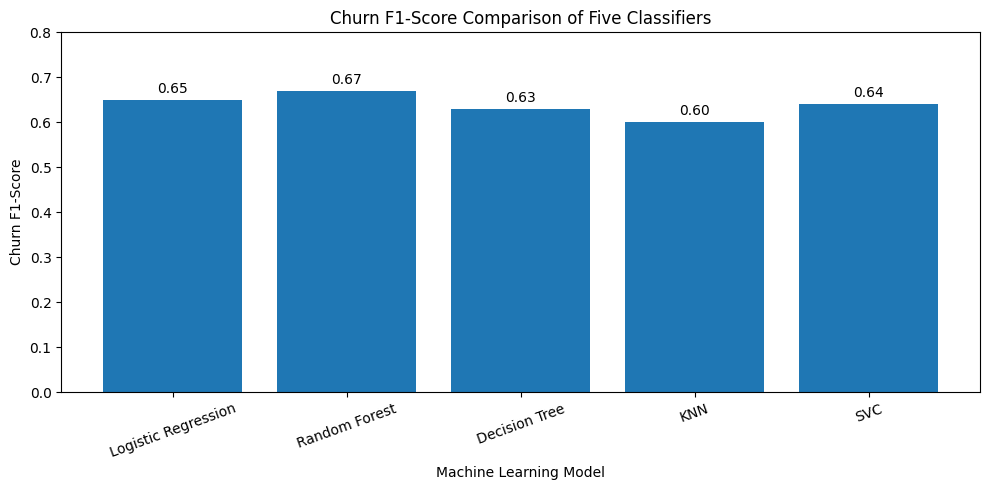

In [138]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    comparison["Model"],
    comparison["Churn F1-score"]
)

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.title("Churn F1-Score Comparison of Five Classifiers")
plt.xlabel("Machine Learning Model")
plt.ylabel("Churn F1-Score")
plt.ylim(0, 0.8)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Feature Importance for RandomForestClassifier

In [146]:
from sklearn.inspection import permutation_importance

# Get  best fine-tuned Random Forest model
best_rf_model = rf_grid.best_estimator_

# Calculate feature importance using the test data
importance = permutation_importance(
    best_rf_model,
    x_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create a DataFrame of feature importance
feature_importance = pd.DataFrame({
    "Feature": x_test.columns,
    "Importance": importance.importances_mean
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
10,InternetService_Fiber optic,0.068991
0,tenure,0.051727
29,Contract_Two year,0.039368
2,TotalCharges,0.020649
28,Contract_One year,0.012481
19,TechSupport_Yes,0.011929
1,MonthlyCharges,0.011574
26,PaymentMethod_Electronic check,0.010589
17,DeviceProtection_Yes,0.006349
24,PaperlessBilling,0.004732


## Top 10 Features

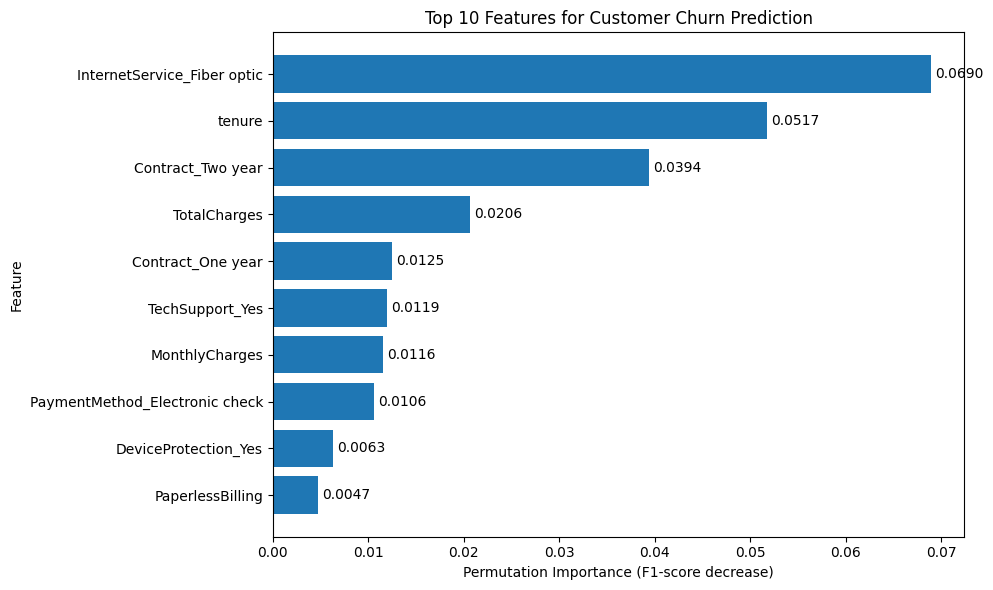

In [147]:
top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.bar_label(bars, fmt="%.4f", padding=3)
plt.title("Top 10 Features for Customer Churn Prediction")
plt.xlabel("Permutation Importance (F1-score decrease)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

#### ### Feature Importance Analysis

Permutation feature importance was used to identify which features were most influential in the model's customer churn predictions. The results showed that **InternetService_Fiber optic** had the highest importance score (0.068991), followed by **tenure** (0.051727) and **Contract_Two year** (0.039368).

Other influential features included TotalCharges, Contract_One year, TechSupport_Yes, and MonthlyCharges. These findings suggest that internet service type, customer tenure, contract type, and billing-related characteristics play an important role in the model's predictions.

The results can help a telecommunications company investigate customer groups that may be at higher risk of churn and develop targeted retention strategies. However, feature importance indicates predictive contribution rather than causation, and the findings should be interpreted in the context of the dataset and model.

# Final Conclusion

In this project, I developed a machine learning model to predict customer churn using the IBM Telco Customer Churn dataset. The project involved data cleaning, preprocessing, training multiple classification algorithms, hyperparameter tuning, model evaluation, and feature importance analysis.

Five classification algorithms were implemented and evaluated: Logistic Regression, Decision Tree, Random Forest, K-Nearest Neighbors (KNN), and Support Vector Classifier (SVC). Their performance was compared using accuracy, precision, recall, F1-score, and ROC-AUC.

Among the five models, the **Fine-Tuned Random Forest Classifier** was selected as the final model because it achieved an accuracy of **78.76%**, a churn F1-score of **0.67**, and a ROC-AUC score of approximately **0.860**. It provided a good balance between identifying customers likely to churn and minimizing incorrect churn predictions. Although KNN achieved higher accuracy and SVC achieved slightly higher churn recall, Random Forest achieved the highest churn F1-score among the evaluated models.

Permutation feature importance was used to understand which features contributed most to the model's predictive performance. The most influential features were **InternetService_Fiber optic**, **tenure**, **Contract_Two year**, **TotalCharges**, and **Contract_One year**. These results suggest that internet service type, customer tenure, contract type, and billing-related characteristics are useful for predicting customer churn. However, feature importance indicates predictive usefulness rather than a direct causal relationship with churn.

The selected model could help telecommunications companies identify customers who may be at risk of leaving and develop targeted customer-retention strategies, such as personalized offers, contract options, and improved customer support. Before deployment, the model would need further validation on new customer data and consideration of the business costs associated with missed churners and incorrect predictions.

In the future, the project could be improved through decision-threshold optimization, further feature analysis, testing on additional customer data, and evaluating the effectiveness of retention strategies. Overall, this project demonstrates how machine learning can support customer churn prediction and help businesses make more informed, data-driven retention decisions.